## Задание 1. Разработка и тестирование определения тональности текста

### Шаг 1. Загрузка и подготовка данных

In [1]:
from pathlib import Path
from datasets import load_dataset
import pandas as pd


DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

SPLITS = [
    "train",
    "test",
    "validation"
]


def save_data(dataset):
    for split_name, split in dataset.items():
        if not (DATA_DIR / f"{split_name}.csv").exists():
            split.to_csv(DATA_DIR / f"{split_name}.csv", index=False)
            print(split_name, len(split))


if all((DATA_DIR / f"{t}.csv").exists() for t in SPLITS):
    print("Данные уже загружены")
else:
    ds = load_dataset("jbeno/sentiment_merged")
    save_data(ds)

train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")
validation_df = pd.read_csv(DATA_DIR / "validation.csv")

df_columns = train_df.columns
head = train_df.head()

print(df_columns)
print(head)

for split, df in zip(SPLITS, [train_df, test_df, validation_df]):
    print('-' * 50)
    print(f"{split.upper()}")
    print(f"Shape: {df.shape}")

    print("\nРаспределение классов:")
    print(df["label"].value_counts(normalize=True))

    print("\nПропуски:")
    print(df.isna().sum())
    print()



/Users/baltabaev/PycharmProjects/Assignment3_NLP/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Данные уже загружены
Index(['sentence', 'label', 'source', 'split'], dtype='str')
                                            sentence     label       source  \
0  Those 2 drinks are part of the HK culture and ...  negative  dynasent_r2   
1  I was told by the repair company that was doin...  negative  dynasent_r1   
2             It is there to give them a good time .   neutral    sst_local   
3  Like leafing through an album of photos accomp...  negative    sst_local   
4         Johnny was a talker and liked to have fun.  positive  dynasent_r1   

   split  
0  train  
1  train  
2  train  
3  train  
4  train  
--------------------------------------------------
TRAIN
Shape: (102097, 4)

Распределение классов:
label
neutral     0.481385
positive    0.304015
negative    0.214600
Name: proportion, dtype: float64

Пропуски:
sentence    0
label       0
source      0
split       0
dtype: int64

--------------------------------------------------
TEST
Shape: (6530, 4)

Распределение классо

### Шаг 2. Предобработка текстов

In [2]:
import nltk
from nltk.corpus import stopwords, wordnet
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

for res in ["punkt", "punkt_tab", "stopwords", "wordnet", "averaged_perceptron_tagger_eng"]:
    nltk.download(res, quiet=True)

1. Токенизация (разделение на слова).
2. Приведение к нижнему регистру.
3. Удаление стоп-слов.
4. Лемматизация (нормализация слов)

In [3]:
NEGATIONS = {"no", "not", "nor", "never"}
STOP_WORDS = set(stopwords.words("english")) - NEGATIONS

lemmatizer = WordNetLemmatizer()


def to_wordnet_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    if tag.startswith("V"):
        return wordnet.VERB
    if tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN


def preprocess(text):
    tokens = word_tokenize(str(text).lower())

    # n't -> not, чтобы отрицание пережило фильтр isalpha
    tokens = ["not" if t == "n't" else t for t in tokens]

    # части речи определяем ДО удаления слов: теггеру нужен контекст
    tagged = nltk.pos_tag(tokens)

    result = []
    for word, tag in tagged:
        # 3. только слова из букв (выкидывает пунктуацию, числа, кавычки)
        if not word.isalpha():
            continue
        # 4. стоп-слова
        if word in STOP_WORDS:
            continue
        # 5. лемматизация с учётом части речи
        result.append(lemmatizer.lemmatize(word, to_wordnet_pos(tag)))

    # 6. строка для TfidfVectorizer
    return " ".join(result)


for text in train_df["sentence"].head(10):
    print(text)
    print("->", preprocess(text))
    print("-" * 50)


CLEAN_PATH = {s: DATA_DIR / f"{s}_clean.parquet" for s in SPLITS}
dfs = {"train": train_df, "test": test_df, "validation": validation_df}

for name, df in dfs.items():
    if CLEAN_PATH[name].exists():
        dfs[name] = pd.read_parquet(CLEAN_PATH[name])
    else:
        df["clean_text"] = df["sentence"].apply(preprocess)
        df.to_parquet(CLEAN_PATH[name], index=False)
    print(name, "пустых после очистки:", (dfs[name]["clean_text"] == "").sum())

train_df, test_df, validation_df = dfs["train"], dfs["test"], dfs["validation"]

Those 2 drinks are part of the HK culture and has years of history. It is so bad.
-> drink part hk culture year history bad
--------------------------------------------------
I was told by the repair company that was doing the car repair that fixing the rim was "impossible" and to replace it.
-> tell repair company car repair fix rim impossible replace
--------------------------------------------------
It is there to give them a good time .
-> give good time
--------------------------------------------------
Like leafing through an album of photos accompanied by the sketchiest of captions .
-> like leaf album photo accompany sketchiest caption
--------------------------------------------------
Johnny was a talker and liked to have fun.
-> johnny talker like fun
--------------------------------------------------
It as burnt to a crisp black flavorless
-> burnt crisp black flavorless
--------------------------------------------------
I called Moveaholics Jason was amazing he even offered

### Шаг 3. Преобразование текстов в векторы
- Bag-of-Words или TF-IDF.
- Для лексиконного метода — вычислите «тональный балл» по словарю.

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer

# биграммы нужны, чтобы модель видела отрицания: "not good" != "good"
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50000)

X_train = vectorizer.fit_transform(train_df["clean_text"])
X_val = vectorizer.transform(validation_df["clean_text"])
X_test = vectorizer.transform(test_df["clean_text"])

y_train, y_val, y_test = train_df["label"], validation_df["label"], test_df["label"]

print("Размер словаря:", len(vectorizer.vocabulary_))
print("X_train:", X_train.shape, "X_val:", X_val.shape, "X_test:", X_test.shape)

Размер словаря: 50000
X_train: (102097, 50000) X_val: (5421, 50000) X_test: (6530, 50000)


**Лексиконный метод.** Словарь — VADER lexicon из NLTK (~7500 слов, у каждого балл от -4 до +4).
Тональный балл предложения = среднее значение баллов найденных слов. Если перед словом стоит отрицание
(`not`, `no`, `never`), знак балла меняется на противоположный.

In [5]:
nltk.download("vader_lexicon", quiet=True)
from nltk.sentiment.vader import SentimentIntensityAnalyzer

LEXICON = SentimentIntensityAnalyzer().lexicon


def lexicon_score(clean_text):
    scores = []
    negate = False
    for word in clean_text.split():
        if word in NEGATIONS:
            negate = True
        elif word in LEXICON:
            scores.append(-LEXICON[word] if negate else LEXICON[word])
            negate = False
    return sum(scores) / len(scores) if scores else 0.0


for df in (train_df, validation_df, test_df):
    df["lex_score"] = df["clean_text"].apply(lexicon_score)

for text in ["good movie", "not good movie", "terrible service", "table chair"]:
    print(f"{text!r:22} -> {lexicon_score(text):.2f}")

'good movie'           -> 1.90
'not good movie'       -> -1.90
'terrible service'     -> -2.10
'table chair'          -> 0.00


### Шаг 4. Обучение модели
**ML-подход:** логистическая регрессия на TF-IDF. Параметр регуляризации `C` подбираем по валидационной выборке.

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

best_f1, model = 0, None
for C in [0.1, 1, 10]:
    candidate = LogisticRegression(C=C, max_iter=1000)
    candidate.fit(X_train, y_train)
    f1 = f1_score(y_val, candidate.predict(X_val), average="macro")
    print(f"C={C:<4} val macro F1 = {f1:.4f}")
    if f1 > best_f1:
        best_f1, model = f1, candidate

print("Лучшее C:", model.C)

C=0.1  val macro F1 = 0.4991
C=1    val macro F1 = 0.6045
C=10   val macro F1 = 0.6064
Лучшее C: 10


**Лексиконный подход:** подбираем два порога на валидации.
`score < low` → negative, `score > high` → positive, иначе → neutral.

In [7]:
import numpy as np


def lexicon_label(scores, low, high):
    return np.select([scores < low, scores > high], ["negative", "positive"], default="neutral")


THRESHOLDS = np.round(np.arange(0, 2.01, 0.1), 1)

best = (0, None, None)
for low in -THRESHOLDS:
    for high in THRESHOLDS:
        pred = lexicon_label(validation_df["lex_score"].values, low, high)
        f1 = f1_score(y_val, pred, average="macro")
        if f1 > best[0]:
            best = (f1, low, high)

best_f1, LOW, HIGH = best
print(f"Лучшие пороги: low={LOW}, high={HIGH}, val macro F1 = {best_f1:.4f}")

Лучшие пороги: low=-0.0, high=0.0, val macro F1 = 0.5294


### Шаг 5. Оценка качества

=== Лексиконный: accuracy=0.5401, macro F1=0.5322
              precision    recall  f1-score   support

    negative      0.628     0.384     0.477      2352
     neutral      0.479     0.562     0.517      1829
    positive      0.541     0.679     0.602      2349

    accuracy                          0.540      6530
   macro avg      0.550     0.542     0.532      6530
weighted avg      0.555     0.540     0.533      6530

=== Логистическая регрессия: accuracy=0.6017, macro F1=0.6005
              precision    recall  f1-score   support

    negative      0.684     0.486     0.568      2352
     neutral      0.491     0.724     0.585      1829
    positive      0.677     0.622     0.648      2349

    accuracy                          0.602      6530
   macro avg      0.617     0.611     0.600      6530
weighted avg      0.627     0.602     0.602      6530



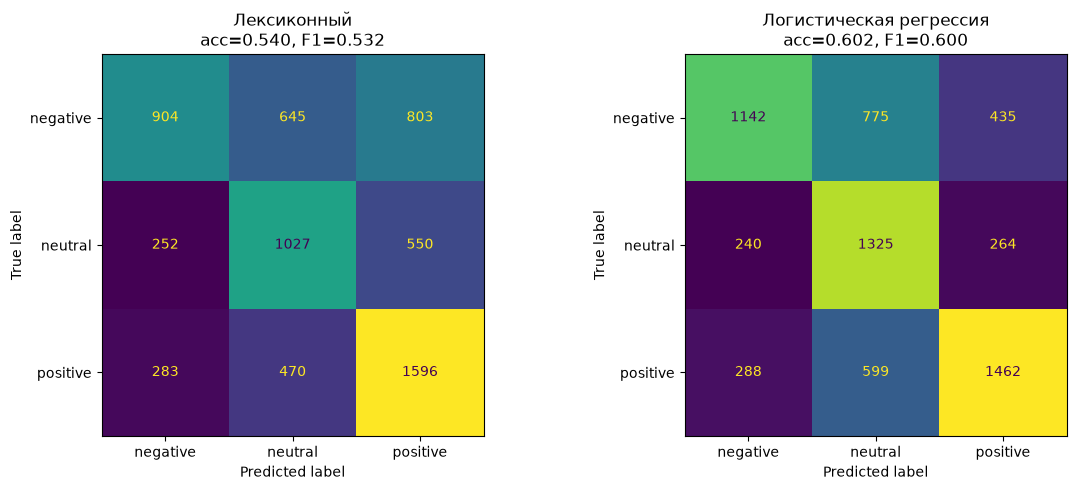

In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

LABELS = ["negative", "neutral", "positive"]

test_df["ml_pred"] = model.predict(X_test)
test_df["lex_pred"] = lexicon_label(test_df["lex_score"].values, LOW, HIGH)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, col) in zip(axes, [("Лексиконный", "lex_pred"), ("Логистическая регрессия", "ml_pred")]):
    acc = accuracy_score(y_test, test_df[col])
    f1 = f1_score(y_test, test_df[col], average="macro")
    print(f"=== {name}: accuracy={acc:.4f}, macro F1={f1:.4f}")
    print(classification_report(y_test, test_df[col], digits=3))
    ConfusionMatrixDisplay.from_predictions(y_test, test_df[col], labels=LABELS, ax=ax, colorbar=False)
    ax.set_title(f"{name}\nacc={acc:.3f}, F1={f1:.3f}")
plt.tight_layout()
plt.show()

### Шаг 6. Анализ ошибок

In [9]:
pd.set_option("display.max_colwidth", 200)

ml_errors = test_df[test_df["ml_pred"] != test_df["label"]]
lex_errors = test_df[test_df["lex_pred"] != test_df["label"]]
print(f"Ошибок ML: {len(ml_errors)} из {len(test_df)}, ошибок лексикона: {len(lex_errors)}")

print("\nПримеры ошибок ML-модели:")
display(ml_errors[["sentence", "label", "ml_pred"]].sample(10, random_state=42))

print("Примеры ошибок лексиконного метода:")
display(lex_errors[["sentence", "label", "lex_pred", "lex_score"]].sample(10, random_state=42))

Ошибок ML: 2601 из 6530, ошибок лексикона: 3003

Примеры ошибок ML-модели:


,sentence,label,ml_pred
3947,"With Danilo Donati 's witty designs and Dante Spinotti 's luscious cinematography , this might have made a decent children 's movie -- if only Benigni had n't insisted on casting himself in the ti...",positive,negative
518,"Fine acting but there is no sense of connecting the dots , just dots .",negative,neutral
626,Treated me like a king when I looked like a bum cause I just got off of work.,positive,negative
5286,"Sluggishly directed by episodic TV veteran Joe Zwick , it 's a sitcom without the snap-crackle .",negative,neutral
3931,"Based on a David Leavitt story , the film shares that writer 's usual blend of observant cleverness , too-facile coincidence and slightly noxious preciousness .",negative,neutral
4815,Ringo sounded great at the concert if you had earplugs in and couldn't hear him sing over the recording,negative,positive
4140,"Nothing Denis has made before , like Beau Travil and Nenette et Boni , could prepare us for this gory , perverted , sex-soaked riff on the cannibal genre .",negative,positive
1189,Sorry - you won't be gifted with the sight of hair from previous guests in the sink at this B&B.,positive,negative
1926,"A journey that 's too random and inconclusive to be compelling , but which Hoffman 's brilliance almost makes worth taking .",neutral,positive
5178,"Movies like this are selling the old European candor , the old wink of ` bold ' revelation .",neutral,negative


Примеры ошибок лексиконного метода:


,sentence,label,lex_pred,lex_score
4732,Is it a total success ?,neutral,positive,2.70
6272,I stopped at Lux after a seeing the 30% off sign.,neutral,negative,-1.20
3018,It is actually located a good distance from the Pacific Ocean.,neutral,positive,1.90
561,This place seemed really legitimate so I went in with super high expectations that I wish had been met.,negative,positive,2.30
1691,The Hours is what movies are supposed to be ...,positive,neutral,0.00
5526,At first we were a little concerned about the price.,negative,neutral,0.00
3023,If they sold their tortillas by the bulk I'd buy them.,positive,neutral,0.00
2499,"I asked to speak to a supervisor, never happened.",negative,neutral,0.00
880,"Some of Seagal 's action pictures are guilty pleasures , but this one is so formulaic that it seems to be on auto-pilot .",negative,positive,0.45
5217,Even die-hard fans of Japanese animation ... will find this one a challenge .,negative,positive,0.80


In [10]:
print("Ошибки ML на предложениях с отрицанием:")
has_negation = test_df["clean_text"].str.contains(r"\b(?:not|no|never)\b")
display(ml_errors[has_negation.loc[ml_errors.index]][["sentence", "label", "ml_pred"]].head(5))

print("Часть ошибок — из-за предобработки (что видит модель после очистки):")
display(ml_errors[["sentence", "clean_text", "label", "ml_pred"]].head(5))

Ошибки ML на предложениях с отрицанием:


,sentence,label,ml_pred
8,There's not a whole lot to say about this place other than the fact that you should already be eating there.,positive,neutral
26,"Not as distinctive or even as humorous as its needs to be to stand out , but it has clearly been made with affection and care .",neutral,positive
31,The staff here are definitely not afraid of arguing/lashing out at customers.,negative,positive
56,"Previous visits merited satisfied customers, including my friend's fiancee who is notoriously hard to please (he's not so much picky as a perfectionist with high expectations for quality food).",positive,neutral
59,Spielberg is the rare director who does not want to invite viewers to gawk at or applaud his special effects .,neutral,positive


Часть ошибок — из-за предобработки (что видит модель после очистки):


,sentence,clean_text,label,ml_pred
0,I had called in advance to see if they offered non-dairy milk and was told they had soy and almond...Yasss!,call advance see offer milk tell soy almond yasss,positive,neutral
7,When I first got this company for my house for cable I was very happy.,first get company house cable happy,positive,neutral
8,There's not a whole lot to say about this place other than the fact that you should already be eating there.,not whole lot say place fact already eat,positive,neutral
9,"It did, however offer up a fun variety of cougars and possums, though!",however offer fun variety cougar possum though,positive,neutral
12,"She answered the phone by saying ""yeah?"".",answer phone say yeah,negative,neutral


**Причины ошибок:**
1. **Нейтральный класс.** Больше всего путаются соседние классы: neutral ↔ positive и neutral ↔ negative.
   Разметка нейтральных предложений субъективна, и граница между классами размыта.
2. **Сарказм и ирония.** Позитивные слова в негативном смысле (*"Great, another two hours of waiting"*). Модель и словарь видят только слова.
3. **Многозначные слова.** Например, *"like"* — это и "нравится" (позитив), и "как/похоже" (нейтрально); *"cheap"* — "дешёвый" или "некачественный".
4. **Ошибки предобработки.** После удаления стоп-слов и лемматизации теряется контекст: короткие предложения превращаются
   в 1–2 слова, а иноязычные предложения в датасете (китайский, французский) почти не распознаются.
5. **Лексиконный метод** (F1 = 0.53 против 0.60 у логистической регрессии). Лучшие пороги оказались low = high = 0,
   т. е. класс определяется просто знаком балла. Метод не знает слов, которых нет в словаре (балл = 0 → neutral), и не учитывает контекст.

**Возможные улучшения:**
- расширить словарь (добавить доменные слова, SentiWordNet);
- более аккуратная обработка отрицаний (сейчас — только следующее тональное слово);
- контекстные модели (BERT, RoBERTa), которые понимают порядок слов и иронию лучше;
- балансировка классов (`class_weight="balanced"`).

### Шаг 7. Визуализация

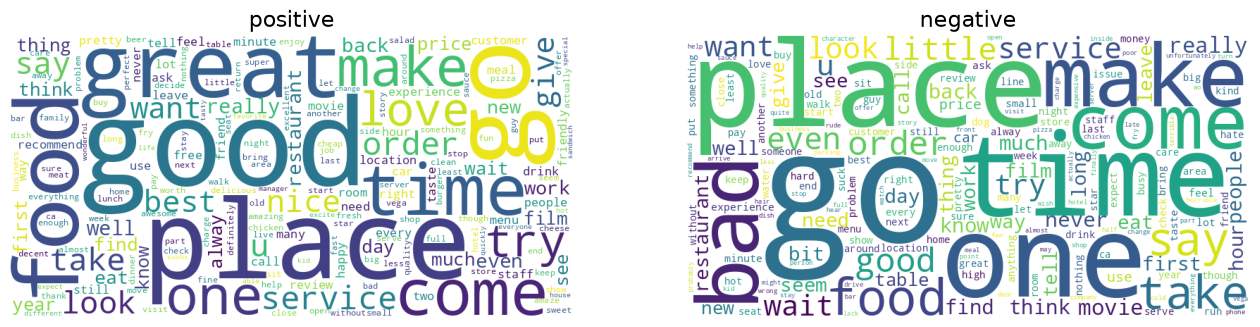

In [11]:
from wordcloud import WordCloud

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, label in zip(axes, ["positive", "negative"]):
    text = " ".join(train_df.loc[train_df["label"] == label, "clean_text"])
    cloud = WordCloud(width=800, height=400, background_color="white", collocations=False).generate(text)
    ax.imshow(cloud)
    ax.set_title(label, fontsize=16)
    ax.axis("off")
plt.show()

In [12]:
TOP_N = 15

feature_names = vectorizer.get_feature_names_out()
top_words = {}
for class_index, label in enumerate(model.classes_):
    top_indices = np.argsort(model.coef_[class_index])[::-1][:TOP_N]
    top_words[label] = [f"{feature_names[i]} ({model.coef_[class_index][i]:.2f})" for i in top_indices]

pd.DataFrame(top_words)

,negative,neutral,positive
0,suck (8.95),good bad (6.99),great (9.15)
1,horrible (8.00),fit look (4.76),amaze (7.86)
2,disgust (8.00),great movie (4.35),love (7.70)
3,disappointed (7.87),side street (4.31),delicious (7.67)
4,piss (7.81),review someone (4.22),excellent (7.42)
5,unfortunately (7.59),never less (4.20),awesome (7.36)
6,not worth (7.20),divert (4.14),nice (7.35)
7,awful (6.69),yelp find (4.10),fabulous (6.88)
8,disappoint (6.66),quite awhile (4.07),excite (6.72)
9,bad (6.41),another not (3.98),not bad (6.59)


In [13]:
def predict_sentiment(sentence):
    clean = preprocess(sentence)
    ml = model.predict(vectorizer.transform([clean]))[0]
    lex = lexicon_label(np.array([lexicon_score(clean)]), LOW, HIGH)[0]
    return ml, lex


for sentence in ["I love this place, the food is amazing!",
                 "The service was not good at all.",
                 "The store opens at 9 am."]:
    ml, lex = predict_sentiment(sentence)
    print(f"{sentence:45} ML: {ml:9} Лексикон: {lex}")

I love this place, the food is amazing!       ML: positive  Лексикон: positive
The service was not good at all.              ML: negative  Лексикон: negative
The store opens at 9 am.                      ML: neutral   Лексикон: neutral


## Задание 2. Автоматическое реферирование
### Шаг 1. Загрузка данных

In [14]:
SUMMARY_DIR = DATA_DIR / "summarization"
EXTRACTIVE_DOCS = ["article1", "article2", "article3"]

docs = {path.stem: path.read_text(encoding="utf-8") for path in sorted(SUMMARY_DIR.glob("article*.txt"))}

for name, text in docs.items():
    print(f"{name}: {len(text.split())} слов")

article1: 428 слов
article2: 700 слов
article3: 636 слов
article4: 528 слов
article5: 316 слов


### Шаг 2. Предобработка
- В файлах предложения разорваны переносами строк, поэтому склеиваем строки. Заголовок — короткая строка без точки после законченного предложения, её удаляем. Также удаляем ссылки вида `[1]`.
- Токенизация предложений — `sent_tokenize` из NLTK.
- Для подсчёта весов каждое предложение очищаем: удаляем спецсимволы и используем функцию `preprocess` из задания 1
  (нижний регистр, стоп-слова, лемматизация). В итоговый реферат идут **оригинальные** предложения.

In [15]:
import re
from nltk.tokenize import sent_tokenize

MIN_HEADING_WORDS = 4
MIN_SENTENCE_WORDS = 6


def is_heading(line, previous_line):
    sentence_ended = previous_line.endswith((".", "!", "?")) or not previous_line
    return sentence_ended and len(line.split()) < MIN_HEADING_WORDS and not line.endswith(".")


def split_sentences(text):
    lines, previous = [], ""
    for line in filter(None, (l.strip() for l in text.splitlines())):
        if not is_heading(line, previous):
            lines.append(line)
            previous = line
    text = " ".join(lines)
    text = re.sub(r"\[\d+\]", "", text)
    text = re.sub(r"\.(?=[A-Z])", ". ", text)
    text = re.sub(r"\s+", " ", text)
    sentences = [s for s in sent_tokenize(text) if len(s.split()) >= MIN_SENTENCE_WORDS]
    return list(dict.fromkeys(sentences))  # в article3 аннотация повторяется дважды


def clean_sentence(sentence):
    return preprocess(re.sub(r"[^a-zA-Z\s]", " ", sentence))


doc_sentences = {name: split_sentences(text) for name, text in docs.items()}
for name, sentences in doc_sentences.items():
    print(f"{name}: {len(sentences)} предложений")

print("\nПример:", doc_sentences["article1"][0])
print("После очистки:", clean_sentence(doc_sentences["article1"][0]))

article1: 29 предложений
article2: 36 предложений
article3: 28 предложений
article4: 28 предложений
article5: 18 предложений

Пример: In recent years, music plagiarism has become a serious issue in the music industry.
После очистки: recent year music plagiarism become serious issue music industry


### Шаг 3. Extractive summarization (TF-IDF)
Каждое предложение — отдельный "документ" для TF-IDF. Вес предложения = сумма TF-IDF весов его слов.
Слово получает большой вес, если оно часто встречается в предложении, но редко в остальных.
Векторизатор обучаем сразу на предложениях всех трёх статей, чтобы веса были сравнимы между документами.

In [16]:
SENTENCES_PER_DOC = 3
SUMMARY_SIZE = 6

sent_df = pd.DataFrame(
    [{"doc": name, "position": i, "sentence": s}
     for name in EXTRACTIVE_DOCS for i, s in enumerate(doc_sentences[name])]
)
sent_df["clean"] = sent_df["sentence"].apply(clean_sentence)

summary_vectorizer = TfidfVectorizer()
sentence_weights = summary_vectorizer.fit_transform(sent_df["clean"])
sent_df["score"] = sentence_weights.sum(axis=1).A1

top_per_doc = (sent_df.sort_values("score", ascending=False)
               .groupby("doc").head(SENTENCES_PER_DOC)
               .sort_values(["doc", "position"]))

for name, group in top_per_doc.groupby("doc"):
    print(f"=== {name}")
    for _, row in group.iterrows():
        print(f"[{row['score']:.2f}] {row['sentence']}")
    print()

=== article1
[3.55] With growing use of the World Wide Web, the revenue loss due to plagiarism and pirate copies has been escalating exponentially.
[3.47] With respect to melody, Korea Entertainment law society conducted a survey to find out what people considered music plagiarism to be.
[3.56] The system receives as input a polyphonic music (PCM data) and outputs information of plagiarized music (music title, time, etc.).

=== article2
[4.20] Recently, the use of various types of multimedia data such as images, videos, and audios has shown its explosive growth, so the content-based search became of great importance.
[4.12] Unlike such previous systems as , our plagiarism detection system has its unique characteristics as follows: • A novel similarity model: it solves the problem of misjudgment by supporting alignment as well as shifting in the similarity model.
[4.38] Music Plagiarism Detection Using Melody Databases 685 • A three-step query processing: it provides fast search ability

In [17]:
final_extractive = top_per_doc.nlargest(SUMMARY_SIZE, "score")

print(f"Итоговый список из {SUMMARY_SIZE} предложений:\n")
for i, (_, row) in enumerate(final_extractive.iterrows(), 1):
    print(f"{i}. ({row['doc']}, {row['score']:.2f}) {row['sentence']}")

extractive_summary = " ".join(final_extractive["sentence"])

Итоговый список из 6 предложений:

1. (article3, 4.51) By using mfcc, entropy and mean energy level we have created a robust fingerprinting algorithm ,which enables us to differentiate copies from original music.these three features have been chosen because of two major considerations.
2. (article2, 4.38) Music Plagiarism Detection Using Melody Databases 685 • A three-step query processing: it provides fast search ability by taking a three-step query processing method, which consists of index searching, window stitching, and post-processing.
3. (article2, 4.20) Recently, the use of various types of multimedia data such as images, videos, and audios has shown its explosive growth, so the content-based search became of great importance.
4. (article2, 4.12) Unlike such previous systems as , our plagiarism detection system has its unique characteristics as follows: • A novel similarity model: it solves the problem of misjudgment by supporting alignment as well as shifting in the similarity

### Шаг 4. Abstractive summarization (BART)
Модель `facebook/bart-large-cnn` (HuggingFace) дообучена на новостях CNN/DailyMail для реферирования.
Каждый из 5 документов реферируем отдельно (ограничение модели — 1024 токена на вход), итоговый реферат —
объединение 5 коротких рефератов. Повторный прогон BART по объединённому тексту пробовали: модель копировала
только первые предложения и теряла 3 статьи из 5.

In [18]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

SUMMARY_MODEL = "facebook/bart-large-cnn"
MAX_INPUT_TOKENS = 1024

bart_tokenizer = AutoTokenizer.from_pretrained(SUMMARY_MODEL)
bart_model = AutoModelForSeq2SeqLM.from_pretrained(SUMMARY_MODEL)


def summarize(text, min_length, max_length):
    inputs = bart_tokenizer(text, return_tensors="pt", truncation=True, max_length=MAX_INPUT_TOKENS)
    output = bart_model.generate(**inputs, num_beams=4, min_length=min_length, max_length=max_length,
                                 no_repeat_ngram_size=3, early_stopping=True)
    return bart_tokenizer.decode(output[0], skip_special_tokens=True)


doc_summaries = {}
for name, sentences in doc_sentences.items():
    doc_summaries[name] = summarize(" ".join(sentences), min_length=30, max_length=80)
    print(f"=== {name}\n{doc_summaries[name]}\n")

W1031 05:45:08.549000 96542 .venv/lib/python3.12/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
[transformers] Please make sure the generation config includes `forced_bos_token_id=0`. 
Loading weights: 100%|██████████| 511/511 [00:00<00:00, 5322.31it/s]


=== article1
In Korea, it is estimated to be more than 2 billion dollar (2009) Music often characterized by its melody, harmony, rhythm and timbre. This system receives PCM data as a query and extracts melody from it. It calculates the melody similarity to the music in the database and retrieves the plagiarized music.

=== article2
This paper addresses the development of a system that detects plagiarism based on similar melody searching. Similar melody searching is to find the melodies similar to a given query melody from a music database. The main purpose of this research is to help composers to avoid unnecessary plagiarism disputes by using the plagiarism detection system in advance.

=== article3
Music plagiarism is not a new phenomena. It has been going for many years. We have come to realise just how many songs are fake. Our project set out to be a beacon of truth to expose plagiarizers.

=== article4
Music-plagiarism is the use or close imitation of an-other authors music without

In [19]:
abstractive_summary = " ".join(doc_summaries.values())
print(abstractive_summary)

In Korea, it is estimated to be more than 2 billion dollar (2009) Music often characterized by its melody, harmony, rhythm and timbre. This system receives PCM data as a query and extracts melody from it. It calculates the melody similarity to the music in the database and retrieves the plagiarized music. This paper addresses the development of a system that detects plagiarism based on similar melody searching. Similar melody searching is to find the melodies similar to a given query melody from a music database. The main purpose of this research is to help composers to avoid unnecessary plagiarism disputes by using the plagiarism detection system in advance. Music plagiarism is not a new phenomena. It has been going for many years. We have come to realise just how many songs are fake. Our project set out to be a beacon of truth to expose plagiarizers. Music-plagiarism is the use or close imitation of an-other authors music without proper acknowledgement. In 2008 alone, 1.4 billion mus

### Шаг 5. Оценка качества
Эталонного реферата нет, поэтому:
- **Сжатие** — во сколько раз реферат короче исходных текстов.
- **ROUGE** с исходным текстом: *recall* показывает, какую долю слов оригинала покрывает реферат (полнота),
  *precision* — какая доля слов реферата взята из оригинала (насколько модель "не выдумывает").

In [20]:
from rouge_score import rouge_scorer

scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=True)


def evaluate_summary(summary, source):
    scores = scorer.score(source, summary)
    row = {"слов в оригинале": len(source.split()), "слов в реферате": len(summary.split())}
    row["сжатие"] = round(row["слов в оригинале"] / row["слов в реферате"], 1)
    for metric, value in scores.items():
        row[f"{metric} P"] = round(value.precision, 3)
        row[f"{metric} R"] = round(value.recall, 3)
    return row


extractive_source = " ".join(" ".join(doc_sentences[name]) for name in EXTRACTIVE_DOCS)
abstractive_source = " ".join(" ".join(s) for s in doc_sentences.values())

pd.DataFrame({
    "Extractive (3 статьи)": evaluate_summary(extractive_summary, extractive_source),
    "Abstractive (5 статей)": evaluate_summary(abstractive_summary, abstractive_source),
}).T

,слов в оригинале,слов в реферате,сжатие,rouge1 P,rouge1 R,rouge2 P,rouge2 R,rougeL P,rougeL R
Extractive (3 статьи),1626.0,186.0,8.7,1.0,0.113,0.973,0.110,0.745,0.084
Abstractive (5 статей),2461.0,224.0,11.0,1.0,0.091,0.956,0.087,0.939,0.085


**Ручная оценка**

| Критерий | Extractive (TF-IDF) | Abstractive (BART) |
|---|---|---|
| Полнота | Предложения о главной теме (обнаружение музыкального плагиата), но выбираются по весу, а не по смыслу — часть ключевых идей может не попасть | Покрывает общую тему всех 5 статей, но детали (конкретные методы, цифры) теряются |
| Связность | Низкая: предложения из разных статей стоят рядом без связок | Высокая: текст читается как единый абзац |
| Корректность | 100% — предложения взяты из оригинала без изменений | Грамматика хорошая, но precision ROUGE < 1: модель может перефразировать неточно или "додумать" факт |

**Вывод:** TF-IDF выбирает длинные предложения с редкими терминами (melody, plagiarism, similarity) — это даёт
точный, но несвязный реферат. BART даёт связный и короткий текст, но его нужно проверять на фактические ошибки.

## Задание 3. Выделение упоминаний в текстах песен
### Шаг 1. Сбор данных
Датасет `amishshah/song_lyrics` (HuggingFace, тексты с Genius, жанр в колонке `tag`).
Датасет большой, поэтому читаем его потоком и берём первые 10 песен для 4 жанров. Результат сохраняем в `data/lyrics.csv`.

In [21]:
LYRICS_PATH = DATA_DIR / "lyrics.csv"
GENRES = ["rap", "rock", "pop", "country"]
SONGS_PER_GENRE = 10


def download_lyrics():
    songs = {genre: [] for genre in GENRES}
    for row in load_dataset("amishshah/song_lyrics", split="train", streaming=True):
        genre = row["tag"]
        if genre in songs and len(songs[genre]) < SONGS_PER_GENRE:
            songs[genre].append({"genre": genre, "title": row["title"], "lyrics": row["lyrics"]})
        if all(len(s) == SONGS_PER_GENRE for s in songs.values()):
            break
    return pd.DataFrame([song for genre in GENRES for song in songs[genre]])


if not LYRICS_PATH.exists():
    download_lyrics().to_csv(LYRICS_PATH, index=False)

lyrics_df = pd.read_csv(LYRICS_PATH)
print(lyrics_df["genre"].value_counts())
lyrics_df.groupby("genre")["title"].apply(list)

genre
rap        10
rock       10
pop        10
country    10
Name: count, dtype: int64


genre
country                                         [1 Corinthians 15:55, Bullets In The Gun, Mine, Rocky Mountain High, Fuck Off, Back to December, All Summer Long, Shouldve Been a Cowboy, Heaven, My Last Yee Haw]
pop                                                                                     [Wordy Rappinghood, Horchata, Heartless, Flashing Lights, Baby, Find Your Love, Anxiety, Fuck You, Up Up  Away, Ego Remix]
rap                                                                    [Killa Cam, Can I Live, Forgive Me Father, Down and Out, Fly In, Lollipop Remix, Im Not You, Family Ties, Rockin and Rollin, Lord You Know]
rock       [Subterranean Homesick Blues, Bohemian Rhapsody, Neighborhood 2 Laïka, White Riot, Leave the Bourbon on the Shelf, Old Man, On the Floor, Jenny Was a Friend of Mine, Rocket Man I Think It’s Going ...
Name: title, dtype: object

### Шаг 2. Предобработка
Удаляем разметку Genius (`[Chorus]`, `[Verse 1]`), затем используем `preprocess` из задания 1:
нижний регистр, токенизация, удаление пунктуации (`isalpha`), стоп-слов и лемматизация.
Дополнительно убираем междометия (oh, yeah, la...) и отрицания — они заполняют весь топ, но смысла не несут.

*Замечание:* в топе рэпа есть имена (killa, cam, dipset) — первые 10 рэп-песен датасета принадлежат одному исполнителю
(Cam'ron), который повторяет своё имя в припевах. Остатки сокращений (*ain't → ai*, *gonna → gon*) — ошибка токенизатора.

In [22]:
from collections import Counter

FILLER_WORDS = {"oh", "yeah", "ooh", "ah", "uh", "hey", "la", "na", "yo", "huh", "woah", "whoa"}
EXCLUDED_WORDS = FILLER_WORDS | NEGATIONS


def lyrics_tokens(text):
    text = re.sub(r"\[.*?\]", " ", text)
    return [word for word in preprocess(text).split() if word not in EXCLUDED_WORDS]


lyrics_df["tokens"] = lyrics_df["lyrics"].apply(lyrics_tokens)

genre_counts = {genre: Counter() for genre in GENRES}
for genre, tokens in zip(lyrics_df["genre"], lyrics_df["tokens"]):
    genre_counts[genre].update(tokens)

for genre, counts in genre_counts.items():
    print(f"{genre:8} слов: {sum(counts.values()):5}, уникальных: {len(counts)}")

rap      слов:  3492, уникальных: 1425
rock     слов:  1227, уникальных: 482
pop      слов:  2184, уникальных: 657
country  слов:  2203, уникальных: 794


### Шаг 3. Частотный анализ — топ-10 слов по жанрам

,rap,rock,pop,country
0,killa (145),riot (32),word (63),like (56)
1,cam (137),go (30),baby (62),get (42)
2,get (77),man (28),wake (49),high (26)
3,like (72),come (27),like (47),last (25)
4,know (44),long (26),know (36),see (23)
5,dipset (39),get (24),light (35),time (21)
6,say (28),time (22),stop (32),ai (21)
7,come (25),think (21),get (32),back (21)
8,nigga (24),look (19),love (28),go (21)
9,see (23),gon (17),find (27),yee (21)


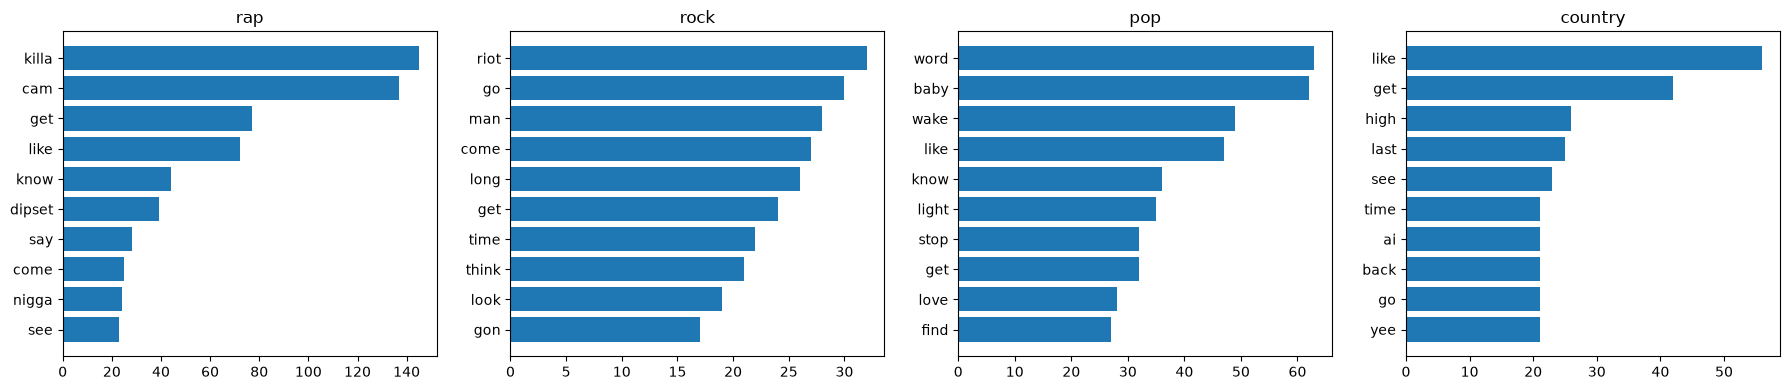

In [23]:
TOP_WORDS = 10

display(pd.DataFrame({genre: [f"{w} ({c})" for w, c in counts.most_common(TOP_WORDS)]
                      for genre, counts in genre_counts.items()}))

fig, axes = plt.subplots(1, len(GENRES), figsize=(18, 4))
for ax, (genre, counts) in zip(axes, genre_counts.items()):
    words, freqs = zip(*counts.most_common(TOP_WORDS))
    ax.barh(words[::-1], freqs[::-1])
    ax.set_title(genre)
plt.tight_layout()
plt.show()

### Шаг 4. Анализ по категориям
Слова в словарях — в начальной форме, так как тексты лемматизированы (`eyes` → `eye`).
Слово *fall* (осень) не включаем: в песнях оно почти всегда глагол "падать" — пример многозначности.

In [24]:
CATEGORIES = {
    "время суток": ["morning", "day", "afternoon", "evening", "night", "midnight", "tonight", "dawn", "sunrise", "sunset"],
    "сезоны года": ["winter", "spring", "summer", "autumn"],
    "части тела": ["eye", "heart", "hand", "face", "head", "lip", "arm", "body", "leg", "hair", "mouth", "skin", "finger", "foot"],
}

for category, words in CATEGORIES.items():
    table = pd.DataFrame({genre: [genre_counts[genre][w] for w in words] for genre in GENRES}, index=words)
    table = table[table.sum(axis=1) > 0]
    table.loc["ВСЕГО"] = table.sum()
    print(f"=== {category}")
    display(table)

=== время суток


,rap,rock,pop,country
morning,1,0,1,0
day,6,5,3,4
night,3,5,6,6
tonight,1,1,1,4
ВСЕГО,11,11,11,14


=== сезоны года


,rap,rock,pop,country
winter,1,0,4,0
spring,0,0,0,2
summer,1,1,1,15
ВСЕГО,2,1,5,17


=== части тела


,rap,rock,pop,country
eye,3,5,2,7
heart,3,0,17,7
hand,3,2,0,3
face,4,5,0,1
head,5,2,2,2
lip,0,0,2,1
arm,1,0,0,4
body,4,1,1,0
leg,2,0,0,0
hair,0,2,0,4


### Шаг 5. Редкие слова
- **В каждом жанре:** слова, которые встречаются в этом жанре не более 3 раз.
- **Во всех жанрах:** слова, суммарная частота которых по всему корпусу не более 3.

In [25]:
MAX_RARE_COUNT = 3
RARE_EXAMPLES = 15

for genre, counts in genre_counts.items():
    rare = sorted(w for w, c in counts.items() if c <= MAX_RARE_COUNT)
    print(f"{genre:8} редких слов: {len(rare)} из {len(counts)} ({len(rare) / len(counts):.0%})")
    print("         примеры:", ", ".join(rare[:RARE_EXAMPLES]))

total_counts = sum(genre_counts.values(), Counter())
rare_everywhere = sorted(w for w, c in total_counts.items() if c <= MAX_RARE_COUNT)
print(f"\nСлов, встречающихся во всём корпусе не более {MAX_RARE_COUNT} раз: {len(rare_everywhere)} из {len(total_counts)}")
print("Примеры:", ", ".join(rare_everywhere[:RARE_EXAMPLES * 2]))

rap      редких слов: 1245 из 1425 (87%)
         примеры: abracadabra, absurd, accessory, account, accustom, ace, activist, actor, adapt, add, addicted, admire, advance, afford, africa
rock     редких слов: 400 из 482 (83%)
         примеры: ache, adventure, ahead, air, alex, alexander, alibi, alleyway, alright, always, anyone, anything, anyway, army, around
pop      редких слов: 507 из 657 (77%)
         примеры: abstract, admit, afford, afloat, ago, aim, air, already, amazin, anger, another, anxieties, anything, anywhere, apartment
country  редких слов: 641 из 794 (81%)
         примеры: aaliyah, across, act, air, alone, along, already, alright, always, amazement, another, answer, arch, arena, aretha

Слов, встречающихся во всём корпусе не более 3 раз: 1824 из 2323
Примеры: aaliyah, abracadabra, abstract, absurd, accessory, account, accustom, ace, ache, across, activist, actor, adapt, add, addicted, admire, admit, advance, adventure, afford, afloat, africa, aggie, ago, ahead, aim, a

## Задание 4. Определение языка текста
### Шаг 1. Сбор данных
Датасет Tatoeba (короткие предложения). 6 языков, две пары похожих: **казахский–русский** (кириллица)
и **испанский–португальский**. Берём по 1000 уникальных предложений на язык.

In [26]:
import csv
from sklearn.model_selection import train_test_split

LANGID_DIR = DATA_DIR / "langid"
LANGUAGES = {"kaz": "kk", "rus": "ru", "eng": "en", "fra": "fr", "spa": "es", "por": "pt"}
SENTENCES_PER_LANG = 1000
RANDOM_STATE = 42


def load_tatoeba(code):
    df = pd.read_csv(LANGID_DIR / f"{code}_sentences.tsv.bz2", sep="\t", names=["id", "lang", "text"],
                     quoting=csv.QUOTE_NONE, on_bad_lines="skip")
    return df.drop_duplicates("text").sample(SENTENCES_PER_LANG, random_state=RANDOM_STATE)[["text", "lang"]]


lang_df = pd.concat([load_tatoeba(code) for code in LANGUAGES], ignore_index=True)
lang_df = lang_df.drop_duplicates("text", keep=False)

lang_train, lang_test = train_test_split(lang_df, test_size=0.2, stratify=lang_df["lang"],
                                         random_state=RANDOM_STATE)

overlap = set(lang_train["text"]) & set(lang_test["text"])
print("train:", len(lang_train), "test:", len(lang_test), "| общих предложений:", len(overlap))
print(lang_df["lang"].value_counts())
lang_df.groupby("lang").head(1)

train: 4800 test: 1200 | общих предложений: 0
lang
kaz    1000
rus    1000
eng    1000
fra    1000
spa    1000
por    1000
Name: count, dtype: int64


,text,lang
0,"Қазақстандық делегацияның мәлімдемесінде біздің еліміздің қарусыздану және ядролық қаруларды таратпау саласындағы ұстанымы көрініс тапқан, ядролық энергияны бейбіт пайдалану, ядролық медицина, ядр...",kaz
1000,Вы читали условие задачи?,rus
2000,My son can neither read nor write yet.,eng
3000,"Il fait nuit, mais il ne dort pas.",fra
4000,Eres el mejor hermano pequeño que pude haber pedido.,spa
5000,Que chatice.,por


### Шаг 2. Предобработка (эксперимент)
- **(а) полная очистка:** нижний регистр, удаление цифр и спецсимволов;
- **(б) минимальная очистка:** только лишние пробелы.

Сравниваем на одной и той же модели (символьные n-граммы + логистическая регрессия).

In [27]:
from sklearn.pipeline import make_pipeline
from sklearn.naive_bayes import MultinomialNB


def clean_full(text):
    return re.sub(r"[\d\W_]+", " ", text.lower()).strip()


def clean_minimal(text):
    return " ".join(text.split())


def char_vectorizer():
    return TfidfVectorizer(analyzer="char_wb", ngram_range=(1, 3))


def word_vectorizer():
    return TfidfVectorizer(analyzer="word")


def run_experiment(vectorizer, classifier, clean):
    pipeline = make_pipeline(vectorizer, classifier)
    pipeline.fit(lang_train["text"].apply(clean), lang_train["lang"])
    pred = pipeline.predict(lang_test["text"].apply(clean))
    return pipeline, pred


for name, clean in [("(а) полная очистка", clean_full), ("(б) минимальная", clean_minimal)]:
    _, pred = run_experiment(char_vectorizer(), LogisticRegression(max_iter=1000), clean)
    print(f"{name:20} accuracy={accuracy_score(lang_test['lang'], pred):.4f}, "
          f"macro F1={f1_score(lang_test['lang'], pred, average='macro'):.4f}")

print("\nПример:", clean_full("Мен 2 жыл бұрын Алматыда тұрдым!"), "|", clean_minimal("Мен 2 жыл бұрын Алматыда тұрдым!"))

(а) полная очистка   accuracy=0.9883, macro F1=0.9883
(б) минимальная      accuracy=0.9875, macro F1=0.9875

Пример: мен жыл бұрын алматыда тұрдым | Мен 2 жыл бұрын Алматыда тұрдым!


**Вывод:** вариант (а) немного лучше (accuracy 0.9883 против 0.9875), но разница — 1 предложение из 1200, потому что главные признаки языка — буквы — сохраняются в обоих вариантах
(регулярное выражение `\W` в Python понимает Unicode, поэтому ә, қ, ғ, ң, ө, ү не удаляются).
Цифры и знаки препинания одинаковы во всех языках и почти не несут информации. Однако некоторые знаки
полезны (например, `¿` и `¡` — только в испанском), а заглавные буквы удваивают число n-грамм. Дальше используем вариант (а).

### Шаг 3–4. Признаки и модели
Символьные n-граммы (1–3) vs слова; Naive Bayes vs логистическая регрессия.

In [28]:
CLEAN = clean_full

results = []
pipelines = {}
for feat_name, make_vectorizer in [("char 1-3", char_vectorizer), ("word", word_vectorizer)]:
    for clf_name, classifier in [("Naive Bayes", MultinomialNB()), ("LogReg", LogisticRegression(max_iter=1000))]:
        pipeline, pred = run_experiment(make_vectorizer(), classifier, CLEAN)
        pipelines[(feat_name, clf_name)] = pipeline
        results.append({"признаки": feat_name, "модель": clf_name,
                        "accuracy": accuracy_score(lang_test["lang"], pred),
                        "macro F1": f1_score(lang_test["lang"], pred, average="macro")})

pd.DataFrame(results).round(4)

,признаки,модель,accuracy,macro F1
0,char 1-3,Naive Bayes,0.9883,0.9883
1,char 1-3,LogReg,0.9883,0.9883
2,word,Naive Bayes,0.9667,0.9670
3,word,LogReg,0.9483,0.9489


**Предобученная модель fastText `lid.176`** (176 языков, обучена на Wikipedia/Tatoeba/SETimes).
Она возвращает метки вида `__label__kk`, переводим их в наши коды. Если модель предсказала другой язык — это ошибка.

In [29]:
import fasttext

FASTTEXT_TO_TATOEBA = {v: k for k, v in LANGUAGES.items()}
fasttext_model = fasttext.load_model(str(LANGID_DIR / "lid.176.ftz"))


def fasttext_predict(texts):
    labels, _ = fasttext_model.predict([t.replace("\n", " ") for t in texts])
    return [FASTTEXT_TO_TATOEBA.get(label[0].replace("__label__", ""), "other") for label in labels]


ft_pred = fasttext_predict(lang_test["text"].tolist())
results.append({"признаки": "-", "модель": "fastText lid.176",
                "accuracy": accuracy_score(lang_test["lang"], ft_pred),
                "macro F1": f1_score(lang_test["lang"], ft_pred, average="macro", labels=list(LANGUAGES))})

pd.DataFrame(results).round(4)

,признаки,модель,accuracy,macro F1
0,char 1-3,Naive Bayes,0.9883,0.9883
1,char 1-3,LogReg,0.9883,0.9883
2,word,Naive Bayes,0.9667,0.9670
3,word,LogReg,0.9483,0.9489
4,-,fastText lid.176,0.9633,0.9716


### Шаг 5. Оценка качества
Матрица ошибок для лучшей модели (символьные n-граммы + логистическая регрессия).

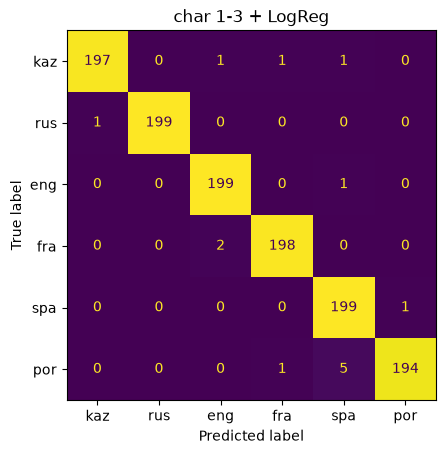

Самые частые ошибки (истинный -> предсказанный):
por  spa    5
fra  eng    2
kaz  fra    1
dtype: int64


In [30]:
from sklearn.metrics import confusion_matrix

best_pipeline = pipelines[("char 1-3", "LogReg")]
lang_test = lang_test.assign(pred=best_pipeline.predict(lang_test["text"].apply(CLEAN)))
LANG_ORDER = list(LANGUAGES)

ConfusionMatrixDisplay.from_predictions(lang_test["lang"], lang_test["pred"], labels=LANG_ORDER, colorbar=False)
plt.title("char 1-3 + LogReg")
plt.show()

cm = pd.DataFrame(confusion_matrix(lang_test["lang"], lang_test["pred"], labels=LANG_ORDER),
                  index=LANG_ORDER, columns=LANG_ORDER)
mistakes = cm.stack()
mistakes = mistakes[mistakes.index.get_level_values(0) != mistakes.index.get_level_values(1)]
print("Самые частые ошибки (истинный -> предсказанный):")
print(mistakes.sort_values(ascending=False).head(3))

In [31]:
lang_errors = lang_test[lang_test["lang"] != lang_test["pred"]]
lang_errors[["text", "lang", "pred"]].head(15)

,text,lang,pred
5500,Tentamos animá-la.,por,spa
4839,Partiremos inmediatamente.,spa,por
5933,Tens de encontrá-la.,por,spa
3959,Gredin !,fra,eng
275,Sen et jeısiń.,kaz,fra
58,Olar túni boıy kóleńke sıaqty júredi.,kaz,eng
5219,Pobre de mim.,por,spa
34,Báribir aman qaldy.,kaz,spa
3905,Thomas habite dans un grand studio.,fra,eng
5595,Ela fará 22 anos no próximo ano.,por,spa


**Почему путаются языки:**
1. **Испанский ↔ португальский** — близкородственные языки с большим количеством общих слов и n-грамм
   (*"que"*, *"de"*, *"no"*, окончания *-ado*, *-os*). Короткое предложение может не содержать ни одной характерной буквы
   (ã, õ, ç для португальского; ñ для испанского).
2. **Казахский ↔ русский** — общая кириллица. Если в предложении нет специальных букв ә, қ, ғ, ң, ө, ү, і, ұ,
   а слова похожи на русские (заимствования, имена), модель может ошибиться.
3. **Казахский на латинице.** В Tatoeba часть казахских предложений записана латиницей
   (*"Sen et jeısiń"*, *"Báribir aman qaldy"*). В обучающей выборке таких мало, поэтому модель
   относит их к французскому/испанскому/английскому.
4. **Французский/английский/испанский** — короткие предложения из имён собственных или интернациональных слов
   (*"Tom!"*, *"Hotel"*) одинаково выглядят на нескольких языках.

**Зависимость accuracy от длины текста.** Из тестовой выборки делаем три варианта:
- **1–3 слова** — первые 1, 2 или 3 слова предложения;
- **1 предложение** — исходный тест;
- **2+ предложения** — к каждому предложению добавляем другое предложение того же языка.

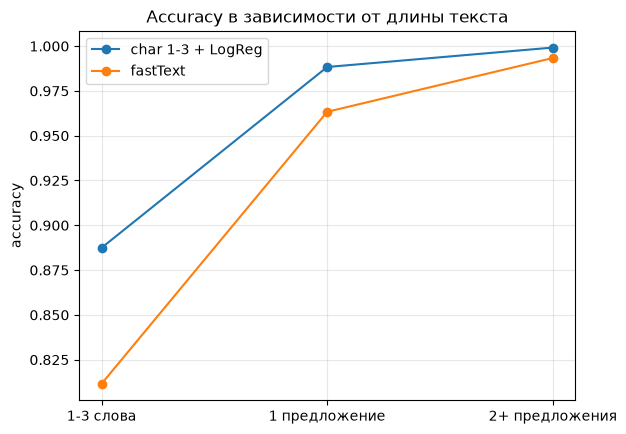

,char 1-3 + LogReg,fastText
1-3 слова,0.8875,0.8117
1 предложение,0.9883,0.9633
2+ предложения,0.9992,0.9933


In [32]:
def first_words(texts):
    return [" ".join(t.split()[:i % 3 + 1]) for i, t in enumerate(texts)]


def two_sentences(df):
    shifted = df.groupby("lang")["text"].transform(lambda s: np.roll(s.values, 1))
    return (df["text"] + " " + shifted).tolist()


length_variants = {
    "1-3 слова": first_words(lang_test["text"]),
    "1 предложение": lang_test["text"].tolist(),
    "2+ предложения": two_sentences(lang_test),
}

length_results = {"char 1-3 + LogReg": [], "fastText": []}
for texts in length_variants.values():
    length_results["char 1-3 + LogReg"].append(
        accuracy_score(lang_test["lang"], best_pipeline.predict([CLEAN(t) for t in texts])))
    length_results["fastText"].append(accuracy_score(lang_test["lang"], fasttext_predict(texts)))

for name, accuracies in length_results.items():
    plt.plot(list(length_variants), accuracies, marker="o", label=name)
plt.ylabel("accuracy")
plt.title("Accuracy в зависимости от длины текста")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

pd.DataFrame(length_results, index=list(length_variants)).round(4)

In [33]:
def predict_language(text):
    probabilities = best_pipeline.predict_proba([CLEAN(text)])[0]
    best_index = probabilities.argmax()
    return best_pipeline.classes_[best_index], probabilities[best_index]


for text in ["Бүгін ауа райы өте жақсы.", "Сегодня хорошая погода.", "Hoje o tempo está bom.",
             "Hoy hace buen tiempo.", "Il fait beau aujourd'hui.", "The weather is nice today."]:
    lang, confidence = predict_language(text)
    print(f"{text:30} -> {lang} ({confidence:.2f})")

Бүгін ауа райы өте жақсы.      -> kaz (0.94)
Сегодня хорошая погода.        -> rus (0.96)
Hoje o tempo está bom.         -> por (0.80)
Hoy hace buen tiempo.          -> spa (0.78)
Il fait beau aujourd'hui.      -> fra (0.84)
The weather is nice today.     -> eng (0.99)


## Контрольные вопросы

1. **Extractive vs abstractive.** Extractive выбирает готовые предложения из исходного текста. Abstractive генерирует
   новый текст своими словами (как человек), может перефразировать и объединять мысли.
2. **Почему TF-IDF/TextRank выбирают предложения, а не слова?** Предложение — минимальная законченная мысль.
   Набор отдельных слов не читается как текст, а целое предложение из оригинала гарантированно грамматически правильное.
3. **Сложности абстрактивного реферирования:** "галлюцинации" (выдуманные факты), повторы, ограничение длины входа
   (BART — 1024 токена), нужны большие модели и данные, сложно оценивать качество.
4. **ROUGE** — метрики пересечения реферата с эталоном: ROUGE-1 (общие слова), ROUGE-2 (общие биграммы),
   ROUGE-L (самая длинная общая подпоследовательность). Recall — какую часть эталона покрыл реферат, precision —
   какая часть реферата есть в эталоне.
5. **Почему грамматика важна для abstractive?** Текст генерируется с нуля, его читает человек; ошибки снижают
   понятность и доверие. У extractive этой проблемы нет — предложения берутся из оригинала.
6. **Лексиконный vs ML.** Лексиконный: словарь с баллами слов, не нужна обучающая выборка, интерпретируемый, но
   не учитывает контекст и домен. ML: учится на размеченных данных, учитывает доменную лексику и сочетания слов,
   но нужны данные и модель хуже переносится на другой домен.
7. **Зачем лемматизация?** Приводит формы слова к одной (*loved, loves, loving → love*). Уменьшает словарь и
   объединяет статистику одного слова.
8. **Confusion matrix** — таблица "истинный класс × предсказанный класс". На диагонали — верные ответы, вне диагонали —
   какие классы с какими путаются.
9. **Почему accuracy вводит в заблуждение?** При дисбалансе классов: если 95% примеров — один класс, модель,
   всегда предсказывающая его, получит 95% accuracy и будет бесполезна. Поэтому смотрим F1 (macro).
10. **Что мешает определению тональности:** сарказм и ирония, отрицания, многозначные слова, доменная лексика,
    смешанная тональность в одном отзыве, опечатки и сленг.
11. **Нормализация vs стандартизация.** Нормализация масштабирует данные в диапазон [0, 1] (min-max).
    Стандартизация приводит к среднему 0 и стандартному отклонению 1 (z-score).
    (В NLP "нормализацией текста" также называют приведение к регистру, лемматизацию и т. п.)
12. **Преимущество TF-IDF перед частотами:** IDF снижает вес слов, которые встречаются во всех документах
    (*the, is*), и повышает вес редких и характерных слов.
13. **Почему abstractive-модели ошибаются грамматически:** генерируют текст токен за токеном, не видя всего
    предложения заранее; обучены на ограниченных данных; ошибки накапливаются при длинной генерации.
14. **ROC vs Precision-Recall.** ROC: TPR против FPR при разных порогах. PR: precision против recall.
    При сильном дисбалансе классов PR-кривая информативнее, так как ROC выглядит оптимистично из-за большого числа TN.
15. **Bag-of-Words:** строим словарь всех слов корпуса, каждый текст — вектор длины словаря, где в позиции слова —
    сколько раз оно встретилось. Порядок слов теряется ("мешок слов").